In [1]:
import os
import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Imports successful.")

Imports successful.


In [ ]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "clean_hr_job_change.csv"
EXPERIMENT_DIR = (PROJECT_ROOT/ "artifacts"/ "experiments"/ "logistic_accuracy")
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)
print("Experiment output:", EXPERIMENT_DIR)

Project root: e:\hr-job-change-ml
Data path: e:\hr-job-change-ml\data\processed\clean_hr_job_change.csv
Experiment output: e:\hr-job-change-ml\artifacts\experiments\logistic_accuracy


In [4]:
df = pd.read_csv(DATA_PATH)
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,company_size,company_type,training_hours,target,experience_missing,experience_numeric,last_new_job_missing,last_new_job_numeric
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,Unknown,Unknown,36,1.0,0,21.0,0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,50-99,Pvt Ltd,47,0.0,0,15.0,0,5.0
2,11561,city_21,0.624,Unknown,No relevent experience,Full time course,Graduate,STEM,Unknown,Unknown,83,0.0,0,5.0,0,0.0
3,33241,city_115,0.789,Unknown,No relevent experience,Unknown,Graduate,Business Degree,Unknown,Pvt Ltd,52,1.0,0,0.0,0,0.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,50-99,Funded Startup,8,0.0,0,21.0,0,4.0


In [6]:
df.shape

(19158, 16)

In [8]:
df.columns.tolist()

['enrollee_id',
 'city',
 'city_development_index',
 'gender',
 'relevent_experience',
 'enrolled_university',
 'education_level',
 'major_discipline',
 'company_size',
 'company_type',
 'training_hours',
 'target',
 'experience_missing',
 'experience_numeric',
 'last_new_job_missing',
 'last_new_job_numeric']

### Recreating Linear regression model from base for comparision

In [9]:
X = df.drop(columns=["enrollee_id","target"])
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentage:")
print(y.value_counts(normalize=True))

Feature shape: (19158, 14)
Target shape: (19158,)

Target distribution:
target
0.0    14381
1.0     4777
Name: count, dtype: int64

Target percentage:
target
0.0    0.750652
1.0    0.249348
Name: proportion, dtype: float64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.15,stratify=y,random_state=42)

print("Training/development set:", X_train.shape)
print("Final test set:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))
print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training/development set: (16284, 14)
Final test set: (2874, 14)

Training target distribution:
target
0.0    0.750676
1.0    0.249324
Name: proportion, dtype: float64

Test target distribution:
target
0.0    0.750522
1.0    0.249478
Name: proportion, dtype: float64


In [11]:
numeric_features = [
    "city_development_index",
    "training_hours",
    "experience_missing",
    "experience_numeric",
    "last_new_job_missing",
    "last_new_job_numeric"
]

categorical_features = [
    "city",
    "gender",
    "relevent_experience",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "company_size",
    "company_type"
]

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ]
)

In [ ]:
baseline_logistic = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            C=0.1,
            class_weight=None,
            max_iter=2000,
            random_state=42
        ))
    ]
)

baseline_logistic.fit(X_train, y_train)

baseline_prob = baseline_logistic.predict_proba(X_test)[:, 1]
baseline_pred = (baseline_prob >= 0.30).astype(int)

In [13]:
baseline_results = {
    "Model": "Current Logistic Regression",
    "Threshold": 0.30,
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred),
    "Recall": recall_score(y_test, baseline_pred),
    "F1": f1_score(y_test, baseline_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, baseline_pred),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob),
    "PR-AUC": average_precision_score(y_test, baseline_prob),
    "Log Loss": log_loss(y_test, baseline_prob),
    "Brier Score": brier_score_loss(y_test, baseline_prob)
}

baseline_results_df = pd.DataFrame([baseline_results])
baseline_results_df

,Model,Threshold,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Current Logistic Regression,0.3,0.788796,0.557895,0.739191,0.635873,0.772238,0.806008,0.545018,0.448365,0.143417


### Trying various new column creation by squaring and muliplyinh existing fields
1. training_hours_log
2. experience_squared
3. last_new_job_squared
4. development_index_squared
5. Interaction features: 
city_development_index × experience,
city_development_index × last_new_job,
experience × last_new_job,
city_development_index × training_hours

In [14]:
def add_engineered_features(data):
    data = data.copy()

    # Log transformation for right-skewed training hours
    data["training_hours_log"] = np.log1p(data["training_hours"])

    # Nonlinear numerical terms
    data["experience_squared"] = data["experience_numeric"] ** 2
    data["last_new_job_squared"] = data["last_new_job_numeric"] ** 2
    data["development_index_squared"] = data["city_development_index"] ** 2

    # Interaction features
    data["development_experience"] = data["city_development_index"] * data["experience_numeric"]
    data["development_last_job"] = data["city_development_index"] * data["last_new_job_numeric"]
    data["experience_last_job"] = data["experience_numeric"] * data["last_new_job_numeric"]
    data["development_training"] = data["city_development_index"] * data["training_hours"]
    return data

In [15]:
X_train_eng = add_engineered_features(X_train)
X_test_eng = add_engineered_features(X_test)

print("Original feature count:", X_train.shape[1])
print("Engineered feature count:", X_train_eng.shape[1])
new_features = [col for col in X_train_eng.columns if col not in X_train.columns]

print("\nNew features:")
for feature in new_features:
    print("-", feature)

Original feature count: 14
Engineered feature count: 22

New features:
- training_hours_log
- experience_squared
- last_new_job_squared
- development_index_squared
- development_experience
- development_last_job
- experience_last_job
- development_training


In [16]:
engineered_numeric_features = numeric_features + [
    "training_hours_log",
    "experience_squared",
    "last_new_job_squared",
    "development_index_squared",
    "development_experience",
    "development_last_job",
    "experience_last_job",
    "development_training"
]

engineered_categorical_features = categorical_features

engineered_numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

engineered_categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]
)

engineered_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            engineered_numeric_preprocessor,
            engineered_numeric_features
        ),
        (
            "cat",
            engineered_categorical_preprocessor,
            engineered_categorical_features
        )
    ]
)

In [17]:
engineered_logistic = Pipeline(
    steps=[
        ("preprocessor", engineered_preprocessor),
        ("model", LogisticRegression(
            C=0.1,
            class_weight=None,
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]
)

engineered_logistic.fit(X_train_eng, y_train)

engineered_prob = engineered_logistic.predict_proba(X_test_eng)[:, 1]
engineered_pred = (engineered_prob >= 0.30).astype(int)

In [18]:
engineered_results = {
    "Model": "Logistic Regression + Engineered Features",
    "Threshold": 0.30,
    "Accuracy": accuracy_score(y_test, engineered_pred),
    "Precision": precision_score(y_test, engineered_pred),
    "Recall": recall_score(y_test, engineered_pred),
    "F1": f1_score(y_test, engineered_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, engineered_pred),
    "ROC-AUC": roc_auc_score(y_test, engineered_prob),
    "PR-AUC": average_precision_score(y_test, engineered_prob),
    "Log Loss": log_loss(y_test, engineered_prob),
    "Brier Score": brier_score_loss(y_test, engineered_prob)
}

experiment_1_df = pd.DataFrame([
    baseline_results,
    engineered_results
])

experiment_1_df

,Model,Threshold,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Current Logistic Regression,0.3,0.788796,0.557895,0.739191,0.635873,0.772238,0.806008,0.545018,0.448365,0.143417
1,Logistic Regression + Engineered Features,0.3,0.788100,0.556723,0.739191,0.635111,0.771774,0.806231,0.546242,0.447694,0.143384


In [19]:
comparison = experiment_1_df.copy()

metrics_to_show = ["Accuracy","Precision","Recall","F1","Balanced Accuracy","ROC-AUC","PR-AUC"]
comparison[["Model"] + metrics_to_show]
baseline_row = experiment_1_df.iloc[0]
experiment_row = experiment_1_df.iloc[1]

print("Experiment 1 improvement")
print("=" * 40)
for metric in metrics_to_show:
    change = experiment_row[metric] - baseline_row[metric]
    print(f"{metric}: {change:+.4f}")

Experiment 1 improvement
Accuracy: -0.0007
Precision: -0.0012
Recall: +0.0000
F1: -0.0008
Balanced Accuracy: -0.0005
ROC-AUC: +0.0002
PR-AUC: +0.0012


### Trying multiple new hyperparameter combination to find better model

In [20]:
accuracy_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

accuracy_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [21]:
logistic_accuracy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]
)

logistic_accuracy_grid = {
    "model__C": [
        0.001,
        0.005,
        0.01,
        0.05,
        0.1,
        0.5,
        1,
        5,
        10,
        50,
        100
    ],
    "model__penalty": [
        "l1",
        "l2"
    ],
    "model__solver": [
        "liblinear"
    ],
    "model__class_weight": [
        None,
        "balanced"
    ]
}

In [22]:
logistic_accuracy_search = GridSearchCV(
    estimator=logistic_accuracy_pipeline,
    param_grid=logistic_accuracy_grid,
    scoring="accuracy",
    cv=accuracy_cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

logistic_accuracy_search.fit(X_train, y_train)

print("Best CV Accuracy:", logistic_accuracy_search.best_score_)
print("\nBest Parameters:")
print(logistic_accuracy_search.best_params_)

Fitting 5 folds for each of 44 candidates, totalling 220 fits
Best CV Accuracy: 0.7801522179784384

Best Parameters:
{'model__C': 1, 'model__class_weight': None, 'model__penalty': 'l1', 'model__solver': 'liblinear'}


In [23]:
tuned_logistic = logistic_accuracy_search.best_estimator_
tuned_prob = tuned_logistic.predict_proba(X_test)[:, 1]

# First evaluate at the standard 0.50 threshold
tuned_pred_05 = (tuned_prob >= 0.50).astype(int)
tuned_results_05 = {
    "Model": "Tuned Logistic Regression",
    "Threshold": 0.50,
    "Accuracy": accuracy_score(y_test, tuned_pred_05),
    "Precision": precision_score(y_test, tuned_pred_05),
    "Recall": recall_score(y_test, tuned_pred_05),
    "F1": f1_score(y_test, tuned_pred_05),
    "Balanced Accuracy": balanced_accuracy_score(y_test, tuned_pred_05),
    "ROC-AUC": roc_auc_score(y_test, tuned_prob),
    "PR-AUC": average_precision_score(y_test, tuned_prob),
    "Log Loss": log_loss(y_test, tuned_prob),
    "Brier Score": brier_score_loss(y_test, tuned_prob)
}

pd.DataFrame([tuned_results_05])

,Model,Threshold,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Tuned Logistic Regression,0.5,0.784273,0.609977,0.375174,0.464594,0.647717,0.806293,0.545926,0.44837,0.143308


### Finding optimized threshold

In [24]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    tuned_logistic,
    X_train,
    y_train,
    cv=accuracy_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF probabilities generated.")
print("Number of predictions:", len(oof_prob))

OOF probabilities generated.
Number of predictions: 16284


In [25]:
thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:
    oof_pred = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_train, oof_pred),
        "precision": precision_score(y_train, oof_pred, zero_division=0),
        "recall": recall_score(y_train, oof_pred, zero_division=0),
        "f1": f1_score(y_train, oof_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_train, oof_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

best_accuracy_row = threshold_df.loc[
    threshold_df["accuracy"].idxmax()
]

print("Best OOF threshold for accuracy:")
print(best_accuracy_row)

Best OOF threshold for accuracy:
threshold            0.390000
accuracy             0.794461
precision            0.586215
recall               0.597044
f1                   0.591580
balanced_accuracy    0.728537
Name: 34, dtype: float64


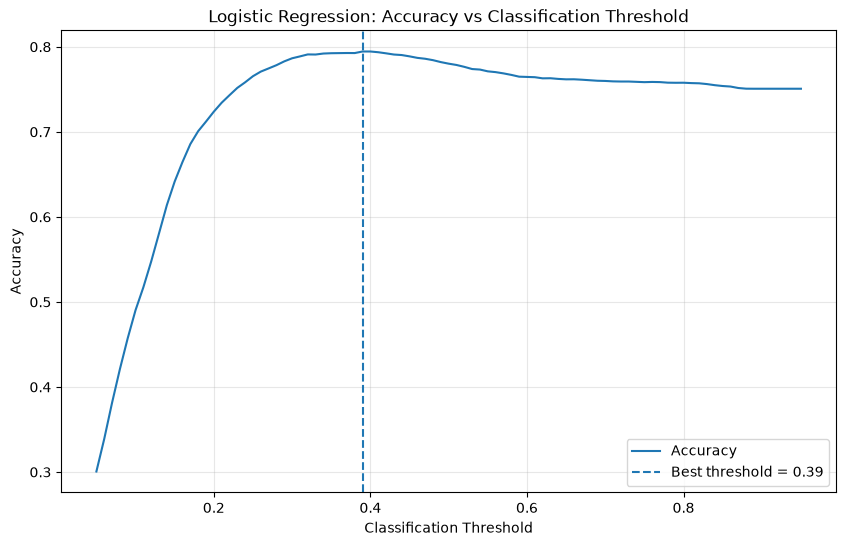

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(threshold_df["threshold"],threshold_df["accuracy"],label="Accuracy")
plt.axvline(best_accuracy_row["threshold"],linestyle="--",label=f"Best threshold = {best_accuracy_row['threshold']:.2f}")

plt.xlabel("Classification Threshold")
plt.ylabel("Accuracy")
plt.title("Logistic Regression: Accuracy vs Classification Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
accuracy_threshold = best_accuracy_row["threshold"]
tuned_pred_accuracy = (tuned_prob >= accuracy_threshold).astype(int)

threshold_test_results = {
    "Model": "Tuned Logistic Regression",
    "Threshold": accuracy_threshold,
    "Accuracy": accuracy_score(y_test, tuned_pred_accuracy),
    "Precision": precision_score(y_test, tuned_pred_accuracy),
    "Recall": recall_score(y_test, tuned_pred_accuracy),
    "F1": f1_score(y_test, tuned_pred_accuracy),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test,
        tuned_pred_accuracy
    ),
    "ROC-AUC": roc_auc_score(y_test, tuned_prob),
    "PR-AUC": average_precision_score(y_test, tuned_prob),
    "Log Loss": log_loss(y_test, tuned_prob),
    "Brier Score": brier_score_loss(
        y_test,
        tuned_prob
    )
}

pd.DataFrame([threshold_test_results])

,Model,Threshold,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Tuned Logistic Regression,0.39,0.795059,0.58377,0.622036,0.602296,0.737305,0.806293,0.545926,0.44837,0.143308


### Changing categorical features, city_developement_index to bins

In [29]:
def add_development_bins(data):
    data = data.copy()

    data["development_index_bin"] = pd.cut(
        data["city_development_index"],
        bins=[0.0,0.60,0.75,0.85,0.92,1.00],
        labels=["Very Low","Low","Medium","High","Very High"],
        include_lowest=True
    )
    return data

In [30]:
X_train_bin = add_development_bins(X_train)
X_test_bin = add_development_bins(X_test)

print(X_train_bin["development_index_bin"].value_counts().sort_index())

development_index_bin
Very Low      611
Low          3619
Medium       1664
High         8220
Very High    2170
Name: count, dtype: int64


In [31]:
bin_numeric_features = numeric_features
bin_categorical_features = categorical_features + ["development_index_bin"]

bin_numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

bin_categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]
)

bin_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            bin_numeric_preprocessor,
            bin_numeric_features
        ),
        (
            "cat",
            bin_categorical_preprocessor,
            bin_categorical_features
        )
    ]
)

In [32]:
bin_logistic = Pipeline(
    steps=[
        ("preprocessor", bin_preprocessor),
        ("model", LogisticRegression(
            C=0.1,
            class_weight=None,
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]
)

bin_logistic.fit(X_train_bin, y_train)
bin_prob = bin_logistic.predict_proba(X_test_bin)[:, 1]
bin_pred = (bin_prob >= 0.30).astype(int)

In [33]:
bin_results = {
    "Model": "Logistic Regression + Development Bins",
    "Threshold": 0.30,
    "Accuracy": accuracy_score(y_test, bin_pred),
    "Precision": precision_score(y_test, bin_pred),
    "Recall": recall_score(y_test, bin_pred),
    "F1": f1_score(y_test, bin_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, bin_pred),
    "ROC-AUC": roc_auc_score(y_test, bin_prob),
    "PR-AUC": average_precision_score(y_test, bin_prob),
    "Log Loss": log_loss(y_test, bin_prob),
    "Brier Score": brier_score_loss(y_test, bin_prob)
}

pd.DataFrame([baseline_results,engineered_results,tuned_results_05,threshold_test_results,bin_results])

,Model,Threshold,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Current Logistic Regression,0.30,0.788796,0.557895,0.739191,0.635873,0.772238,0.806008,0.545018,0.448365,0.143417
1,Logistic Regression + Engineered Features,0.30,0.788100,0.556723,0.739191,0.635111,0.771774,0.806231,0.546242,0.447694,0.143384
2,Tuned Logistic Regression,0.50,0.784273,0.609977,0.375174,0.464594,0.647717,0.806293,0.545926,0.448370,0.143308
3,Tuned Logistic Regression,0.39,0.795059,0.583770,0.622036,0.602296,0.737305,0.806293,0.545926,0.448370,0.143308
4,Logistic Regression + Development Bins,0.30,0.788448,0.557429,0.737796,0.635054,0.771541,0.805925,0.545546,0.448046,0.143212


### Saving Experiment Model

In [34]:
import pickle
import json

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
logistic_accuracy_model_path = (EXPERIMENT_DIR / "logistic_accuracy_optimized.pkl")

with open(logistic_accuracy_model_path, "wb") as f:
    pickle.dump(logistic_accuracy_search.best_estimator_, f)

logistic_params_path = EXPERIMENT_DIR / "best_parameters.json"
with open(logistic_params_path, "w") as f:
    json.dump(logistic_accuracy_search.best_params_,f,indent=4)

logistic_cv_summary = pd.DataFrame([{
    "experiment": "Logistic Regression Accuracy Optimization",
    "best_cv_accuracy": logistic_accuracy_search.best_score_,
    "best_parameters": str(logistic_accuracy_search.best_params_)
}])

logistic_cv_summary.to_csv(EXPERIMENT_DIR / "cv_summary.csv",index=False)
print("Logistic Regression experiment model saved:")
print(logistic_accuracy_model_path)

print("\nExperiment artifacts:")
for file in sorted(EXPERIMENT_DIR.iterdir()):
    print(" -", file.name)

Logistic Regression experiment model saved:
e:\hr-job-change-ml\artifacts\experiments\logistic_accuracy\logistic_accuracy_optimized.pkl

Experiment artifacts:
 - best_parameters.json
 - cv_summary.csv
 - logistic_accuracy_optimized.pkl


In [35]:
with open(logistic_accuracy_model_path, "rb") as f:
    loaded_logistic_experiment = pickle.load(f)

print(type(loaded_logistic_experiment))

<class 'sklearn.pipeline.Pipeline'>
